# quick exploration of cell tracks dataframes, anvil/cell features

- input: monthly datasets for ICON and OBS in June or December 2023
- output: evaluation plots, boxplots and histograms & sister/cores plot

In [1]:

import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import os 

import sys 
sys.path.append("../tools")
import defs_application 
import plots_figures as plots_figs

In [2]:
inputdir = Path("../output/final_dataframes")

models = ["ICON","OBS"]
timeperiods = ["JUNE","DECEMBER"]

month_label = "June"
month = "JUNE"


savedir = Path(f"../output/plots/eval/{month}")
savedir.mkdir(parents=True, exist_ok=True)


var_order_cell_features= defs_application.var_order_cell_features
var_order_anvil_features= defs_application.var_order_anvil_features
var_order_domain = defs_application.var_order_domain

var_order_tracks_cellonly = defs_application.var_order_tracks_cellonly

In [3]:
cellfeatures = {}
anvilfeatures = {}
cells = {}
domain = {}

for model in models:
    cellfeatures[model] = {}
    anvilfeatures[model] = {}
    cells[model] = {}
    domain[model] ={}

    for timeperiod in timeperiods:

        cellfeatures[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"cell_features_{model}_{timeperiod}.h5"),
            key="table"
        )

        anvilfeatures[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"anvil_features_{model}_{timeperiod}.h5"),
            key="table"
        )

        cells[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"cell_tracks_{model}_{timeperiod}.h5"),
            key="table"
        )

        domain[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"domain_{model}_{timeperiod}.h5"),
            key="table"
        )
        
        for col in ["cell_area_sum", "anvil_area_sum"]:
            if col in domain[model][timeperiod].columns:
                domain[model][timeperiod][col] = domain[model][timeperiod][col] * 1e-6



# plotting functions

In [4]:
counts_per_day = (
    cellfeatures["OBS"]["JUNE"][["time"]]
    .assign(day=lambda d: d["time"].dt.floor("D"))
    .groupby("day").size()
)
counts_per_day.describe()

count     30.000000
mean     228.233333
std       40.185504
min      147.000000
25%      201.500000
50%      221.000000
75%      262.000000
max      304.000000
dtype: float64

# cells 

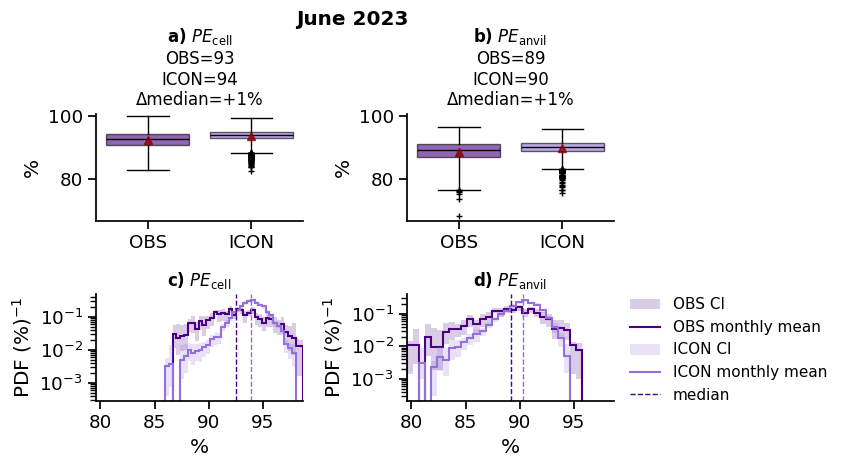

In [5]:
variables = [ "PE_cell","PE_anvil"]
VAR_META_ICON = defs_application.make_var_meta(variables, source="ICON")
VAR_META_OBS = defs_application.make_var_meta(variables, source="OBS")
import re
from string import ascii_lowercase

sns.set_context("notebook", font_scale = 1.2)

fig, ax = plt.subplots(2, 2, figsize=(8, 5))

# row 0: boxplots for both variables
plots_figs.quick_boxplots(cells, var_meta_icon=VAR_META_ICON, var_meta_obs=VAR_META_OBS,
                 vars_to_plot=variables, ncols=2, title="",
                 month=month, fig=fig, axes=ax[0, :], subplotlabelpre=None)

# row 1: histograms for both variables
plots_figs.quick_histograms(cells, var_meta_icon=VAR_META_ICON, var_meta_obs=VAR_META_OBS,
                 vars_to_plot=variables, vars_not_plot=["time","num_cell","feature"], ncols=2,
                 nbins=50, y_label="PDF", title="",
                 month=month, groupbykey="M", groupbykey_for_uncertainty="D",
                 density=True, uncertainty=True,
                 fig=fig, axes=ax[1, :], subplotlabelpre=None, addspace="\n\n", adaptsizes=False)

# quick_histograms already added a fig-level legend at a hardcoded offset — remove it
handles, labels = ax[1, 0].get_legend_handles_labels()
if fig.legends:
    fig.legends[-1].remove()

# boxplots use the short 'label'; swap in 'label_long' to match the histograms
for var, a in zip(variables, ax[0, :]):
    short = VAR_META_ICON[var]["label"]
    long_ = VAR_META_ICON[var]["label"]
    a.set_title(a.get_title().replace(short, long_), fontweight="normal")

# reading order now just matches ax.flat: (a)=box var0, (b)=box var1, (c)=hist var0, (d)=hist var1
label_pattern = re.compile(r'^(?:\$\\mathbf\{\(?[a-z]\)\}\$|\(?[a-z]\))')

axes_reading_order = list(ax.flat)
letters = list(ascii_lowercase[:len(axes_reading_order)])
for letter, a in zip(letters, axes_reading_order):
    old_title = a.get_title()
    new_label = r'$\mathbf{' + letter + r')}$'          # bold "a)"
    if label_pattern.match(old_title):
        new_title = label_pattern.sub(lambda m: new_label, old_title, count=1)
    else:
        new_title = f"{new_label} {old_title}"          # no label found: prepend one
    a.set_title(new_title, fontweight="normal")

# shared y-axis for boxplots (row 0)
ylims = [a.get_ylim() for a in ax[0, :]]
ymin, ymax = min(y[0] for y in ylims), max(y[1] for y in ylims)
for a in ax[0, :]:
    a.set_ylim(ymin, ymax)

# shared x-axis for histograms (row 1)
xlims = [a.get_xlim() for a in ax[1, :]]
xmin, xmax = min(x[0] for x in xlims), max(x[1] for x in xlims)
for a in ax[1, :]:
    a.set_xlim(xmin, xmax)

fig.tight_layout(rect=[0, 0, 0.80, 0.97])

fig.legend(handles, labels,
           loc="center left",
           bbox_to_anchor=(0.78, 0.25),   # x = right edge of the plot area, y = vertical middle
           ncol=1,                        # one column, stacked vertically
           frameon=False)

fig.suptitle(f"{month_label} 2023", fontweight="bold", y=0.93,x = 0.45)  # x=0.40 centers it over the plots, not the whole figure

plt.savefig(os.path.join(savedir, f"PE_pdf_box_join_{month}.pdf"), bbox_inches="tight")
plt.show()

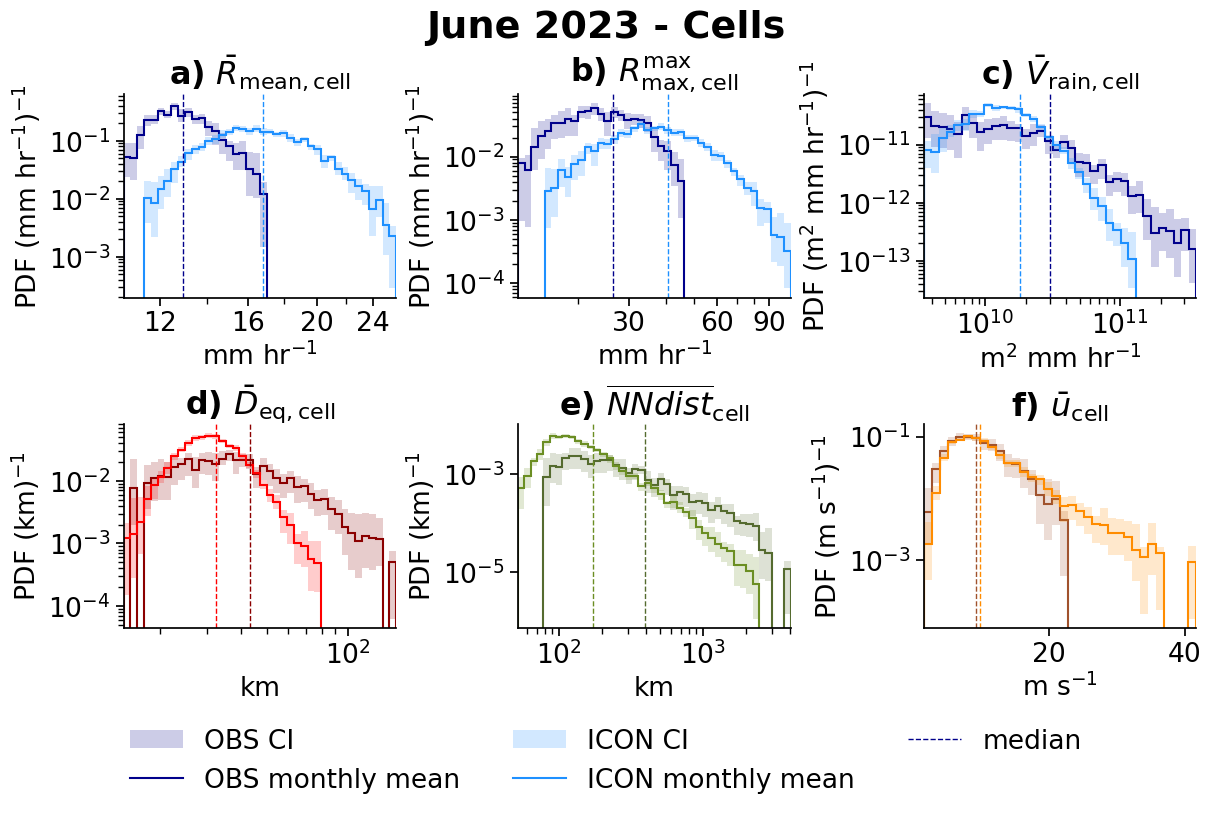

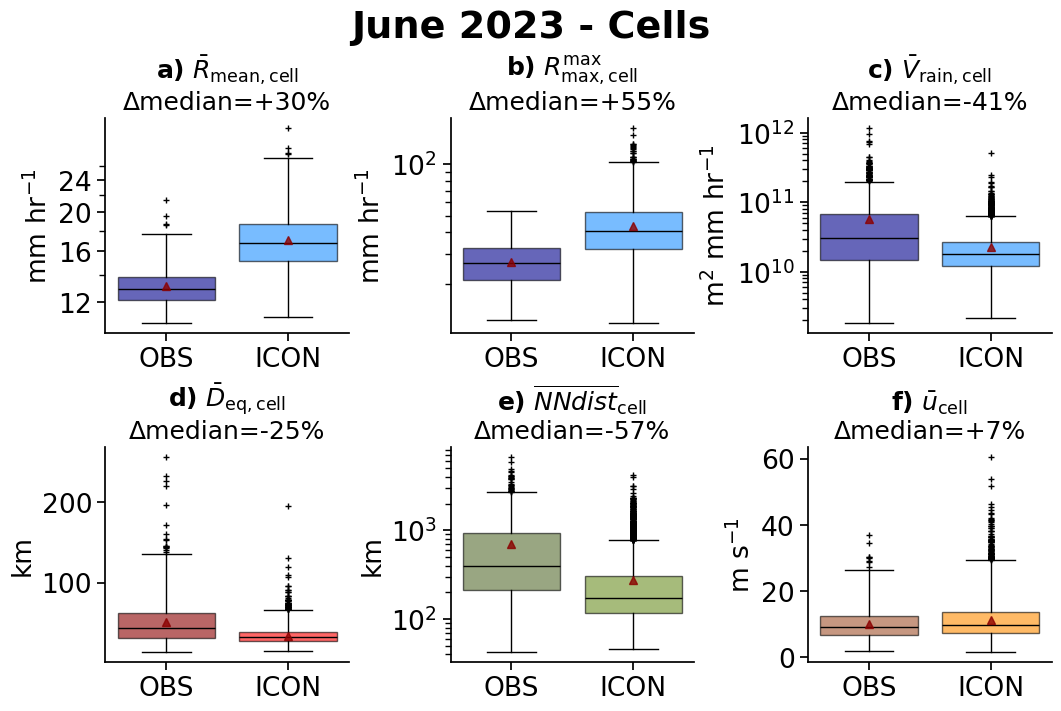

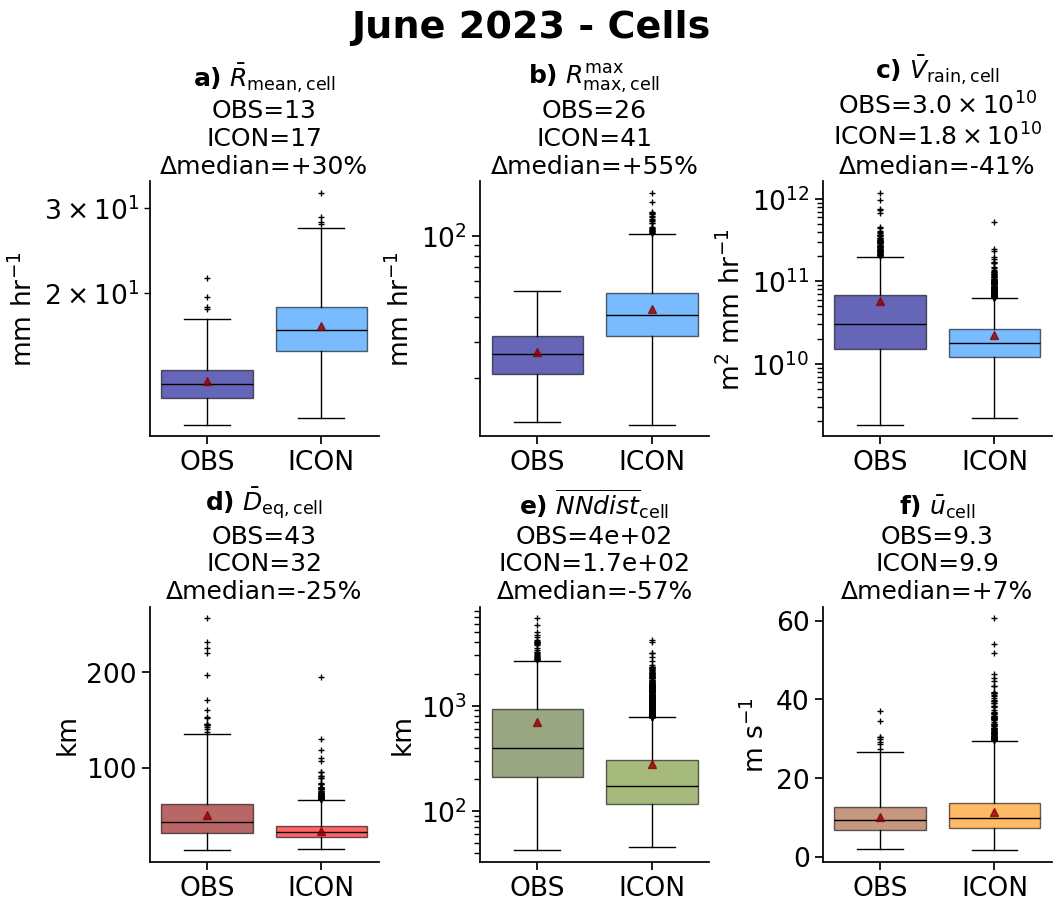

In [6]:
var_order_tracks_cellonly = ['mean_precip_cell_mean',
 'max_precip_cell_max',
 'rain_volume_cell_mean',
 'd_eq_cell_mean',
 'min_dist_cell_km_mean',
 'velo_cell_mean'
]

VAR_META_ICON= defs_application.make_var_meta(var_order_tracks_cellonly, source="ICON")
VAR_META_OBS= defs_application.make_var_meta(var_order_tracks_cellonly, source="OBS")

# pdfs
plots_figs.quick_histograms(cells,
                 var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS,
                 vars_to_plot = var_order_tracks_cellonly,
                 vars_not_plot = ["time","num_cell","feature"],
                 nbins = 50, y_label = "PDF", title = f"{month_label} 2023 - Cells",
                month = month, groupbykey = "M" ,groupbykey_for_uncertainty = "D", 
                                 density = True, uncertainty = True)
plt.savefig(os.path.join(savedir,f"celltracks_hist_{month}.pdf"),bbox_inches="tight")
plt.show()


# boxplots
plots_figs.quick_boxplots_reduced(cells,      var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS,vars_to_plot = var_order_tracks_cellonly,
                         title = f"{month_label} 2023 - Cells",month = month,
                         fontsizesubplots = 18)
plt.savefig(os.path.join(savedir,f"celltracks_box_{month}.pdf"),bbox_inches="tight")

plt.show()

# for medians
plots_figs.quick_boxplots(cells,      var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS,vars_to_plot = var_order_tracks_cellonly,
                         title = f"{month_label} 2023 - Cells",month = month,
                         fontsizesubplots = 18)
plt.show()


# Anvil fetaures

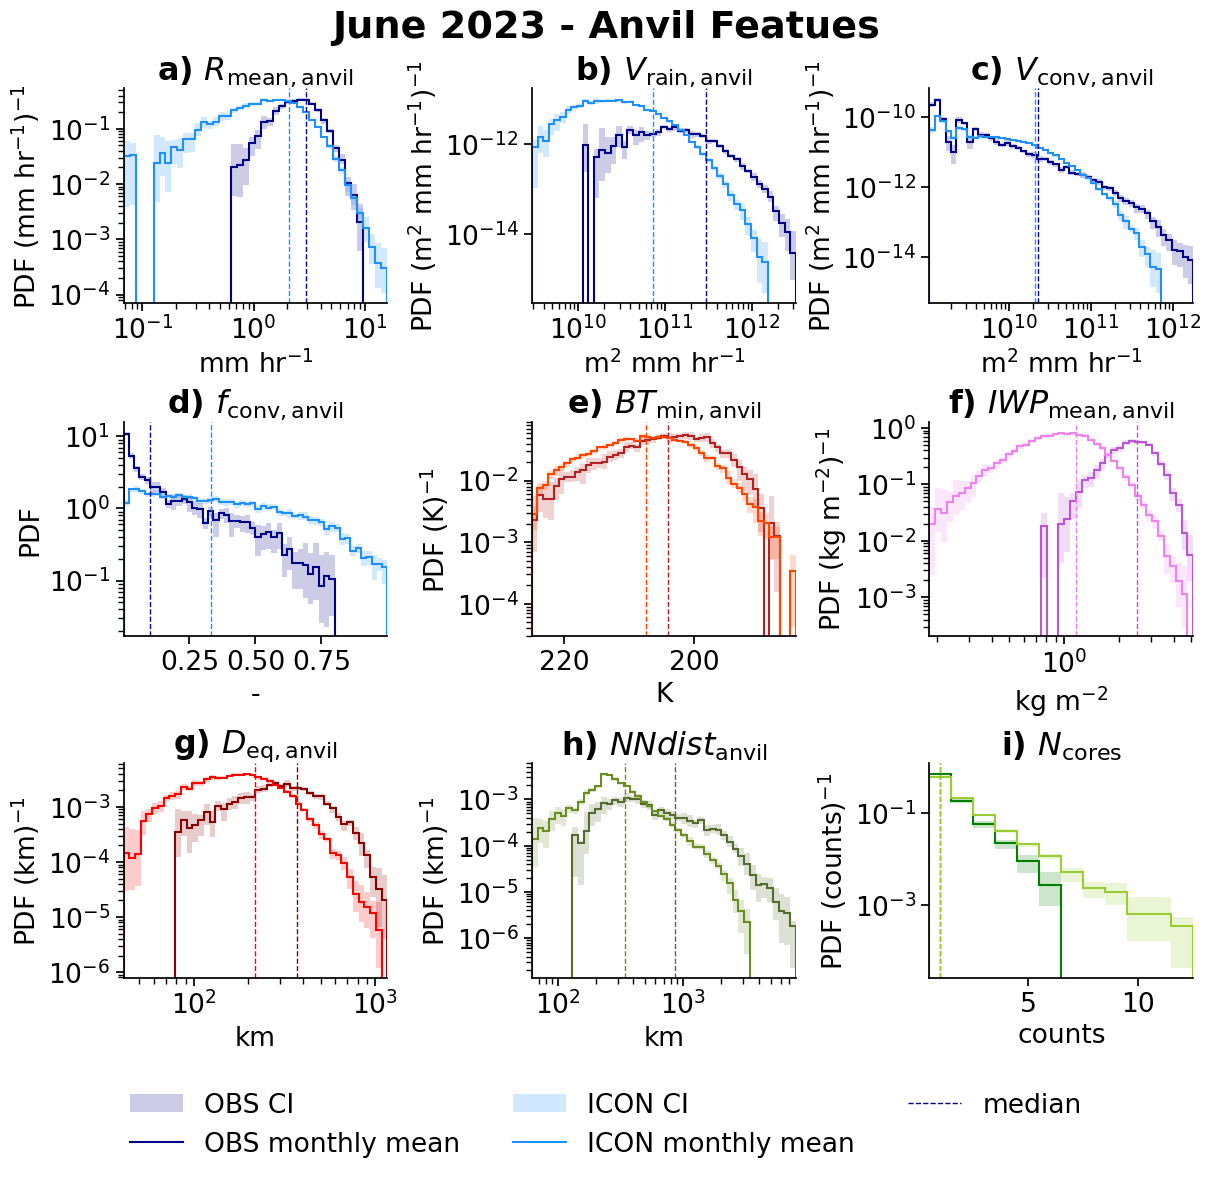

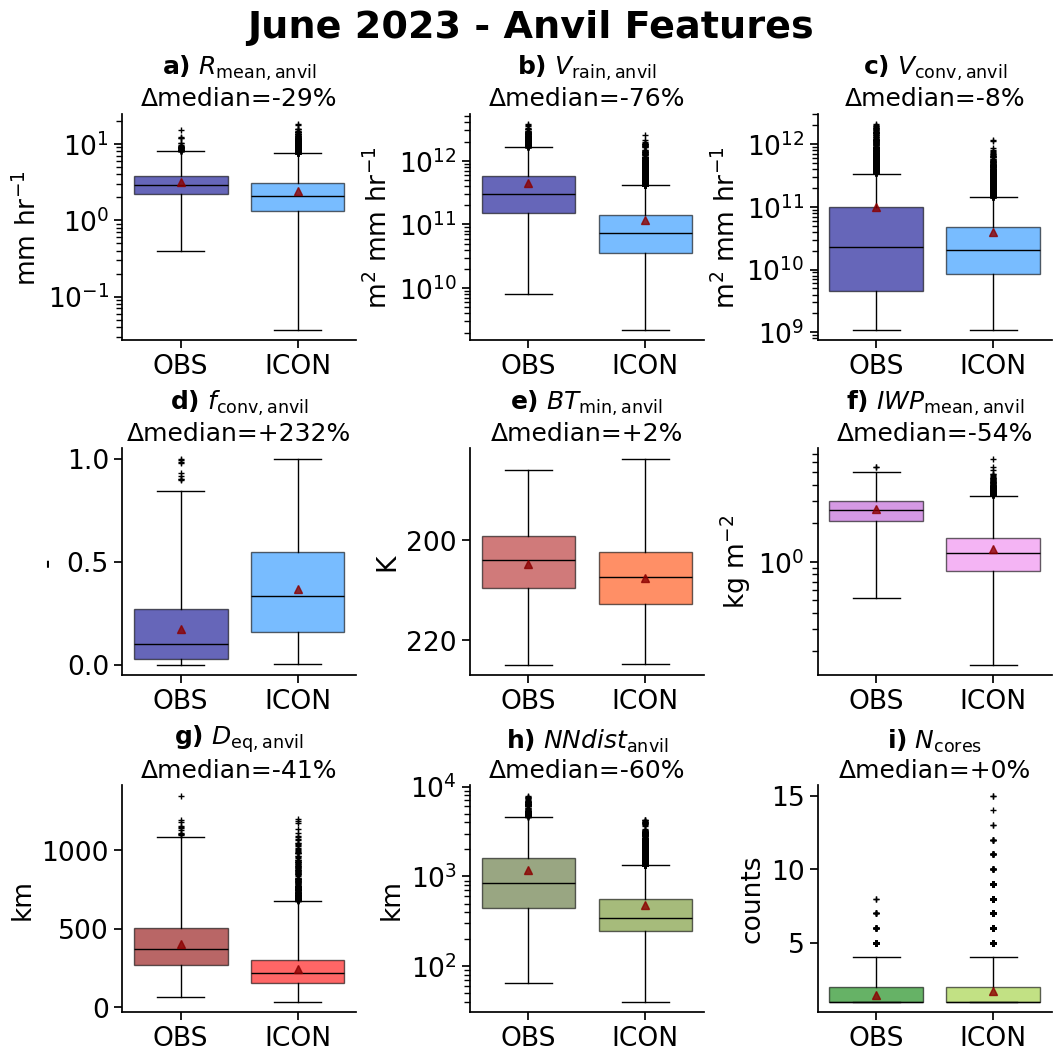

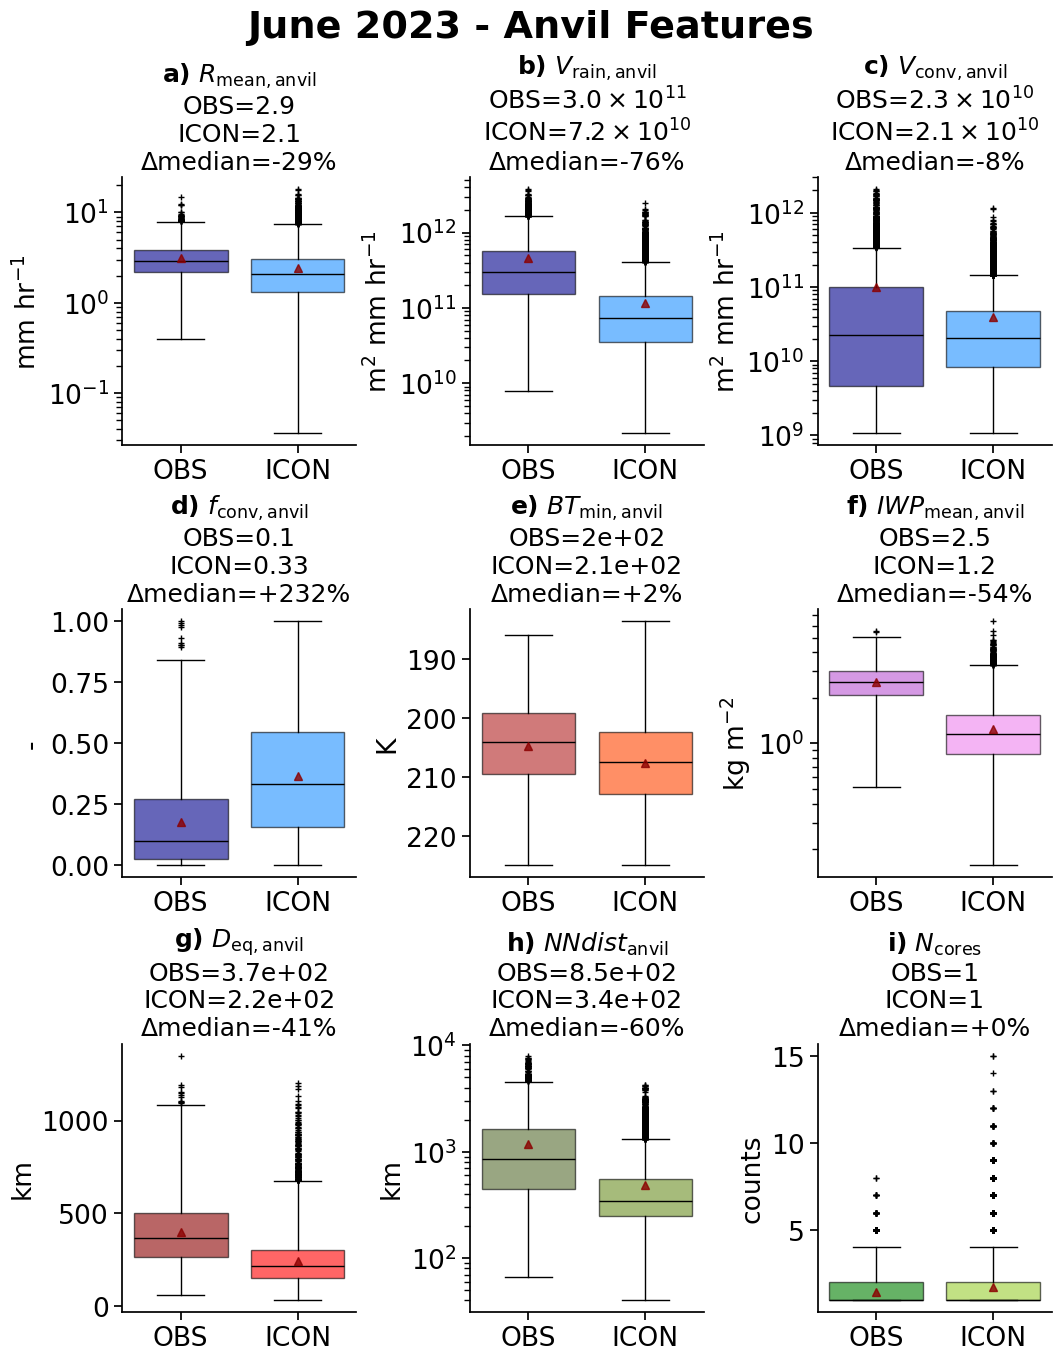

In [7]:
var_order_anvil_features = ['mean_precip_anvil',
 'rain_volume_anvil',
 'convective_rain_volume_anvil',
 'fraction_convection_rain_volume_anvil',
                             'min_tb_anvil',
                             'mean_iwp_anvil',
 'd_eq_anvil',
 'min_dist_anvil_km',
 'n_children_anvil',


 # 'max_iwp_anvil',
 # 'iwp_volume_anvil'
                           ]
VAR_META_ICON= defs_application.make_var_meta(var_order_anvil_features, source="ICON")#,label_map= None)
VAR_META_OBS= defs_application.make_var_meta(var_order_anvil_features, source="OBS")#,label_map= None)

# pdfs 
plots_figs.quick_histograms(anvilfeatures,
                var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS,
                 vars_to_plot = var_order_anvil_features, vars_not_plot = ["time","num_anvil","feature_anvil"]
                 ,nbins = 50,y_label = "PDF",title = f"{month_label} 2023 - Anvil Featues",month = month, ncols = 3,
                            groupbykey = "M" ,groupbykey_for_uncertainty = "D", 
                           )
plt.savefig(os.path.join(savedir,f"anvilfeatures_hist_{month}.pdf"),bbox_inches="tight")
plt.show()

# boxplots
plots_figs.quick_boxplots_reduced(anvilfeatures,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_anvil_features,vars_not_plot = ["time","num_anvil","feature_anvil"],
                          title = f"{month_label} 2023 - Anvil Features",month = month, ncols = 3,
                         fontsizesubplots = 18)
plt.savefig(os.path.join(savedir,f"anvilfeatures_box_{month}.pdf"),bbox_inches="tight")

plt.show()


# for medians
plots_figs.quick_boxplots(anvilfeatures,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_anvil_features,vars_not_plot = ["time","num_anvil","feature_anvil"],
                          title = f"{month_label} 2023 - Anvil Features",month = month, ncols = 3,
                         fontsizesubplots = 18)

plt.show()

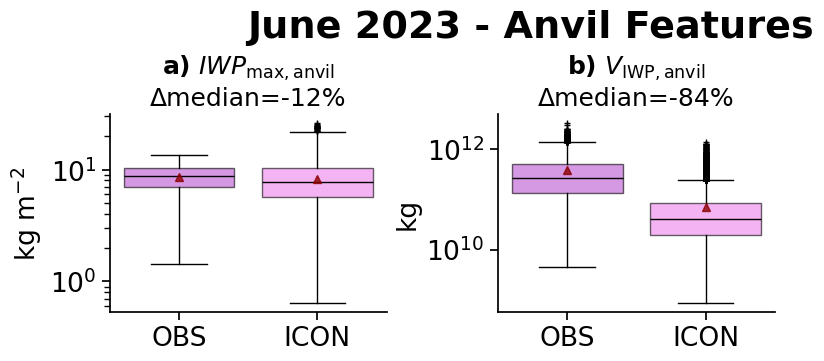

In [8]:
var_order_anvil_features = [
 'max_iwp_anvil',
 'iwp_volume_anvil'
                           ]
VAR_META_ICON= defs_application.make_var_meta(var_order_anvil_features, source="ICON")#,label_map= None)
VAR_META_OBS= defs_application.make_var_meta(var_order_anvil_features, source="OBS")#,label_map= None)

# pdfs 

# boxplots
plots_figs.quick_boxplots_reduced(anvilfeatures,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_anvil_features,vars_not_plot = ["time","num_anvil","feature_anvil"],
                          title = f"{month_label} 2023 - Anvil Features",month = month, ncols = 3,
                         fontsizesubplots = 18)
plt.savefig(os.path.join(savedir,f"add_anvilfeatures_box_{month}.pdf"),bbox_inches="tight")

plt.show()

# cell feature

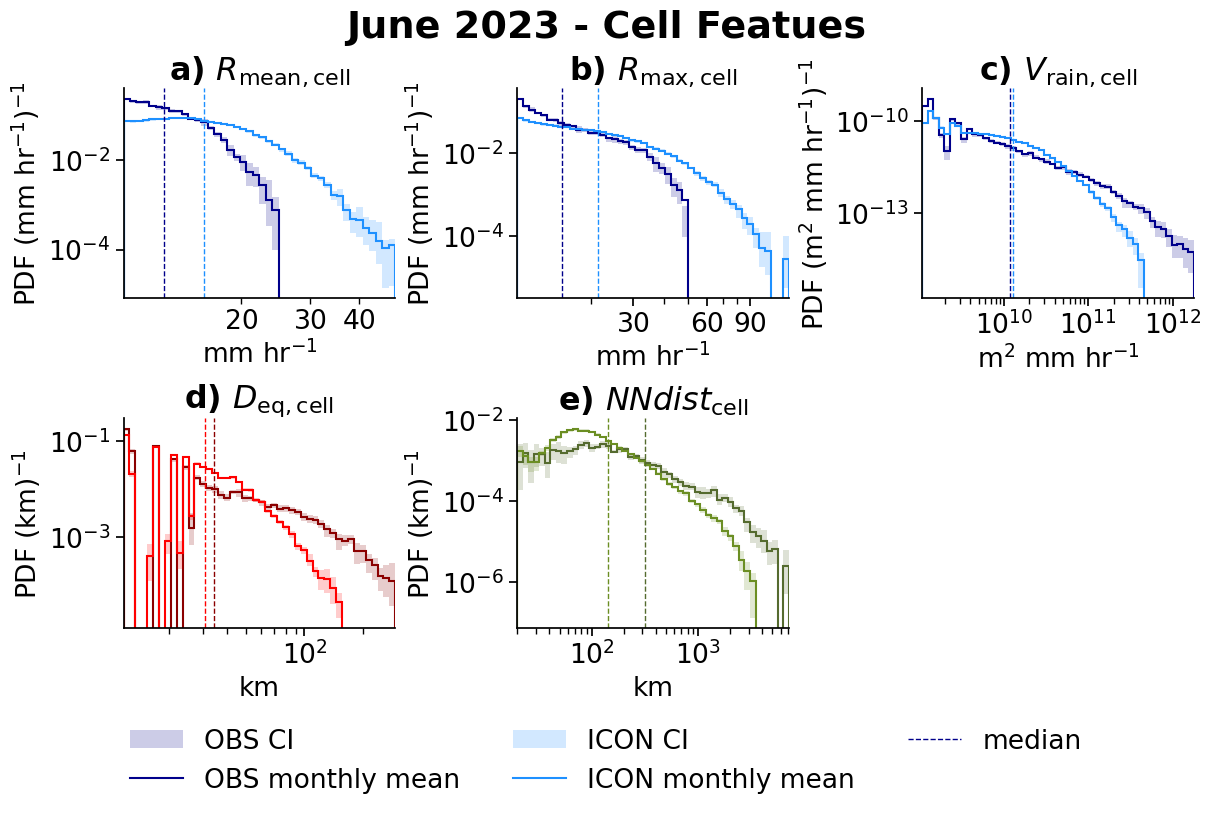

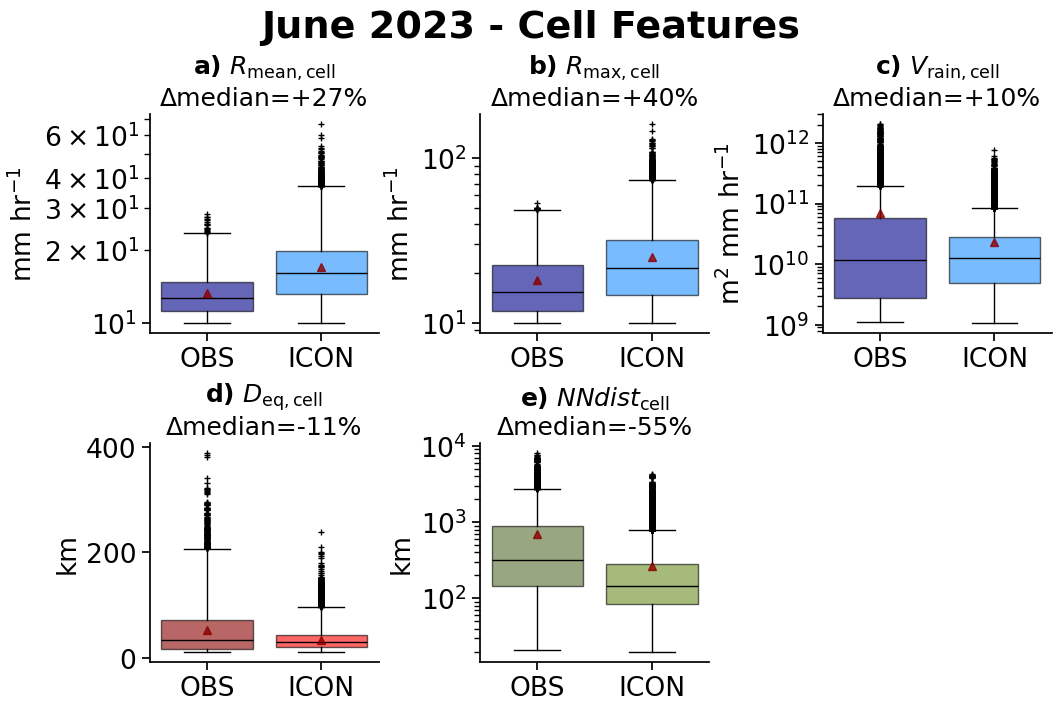

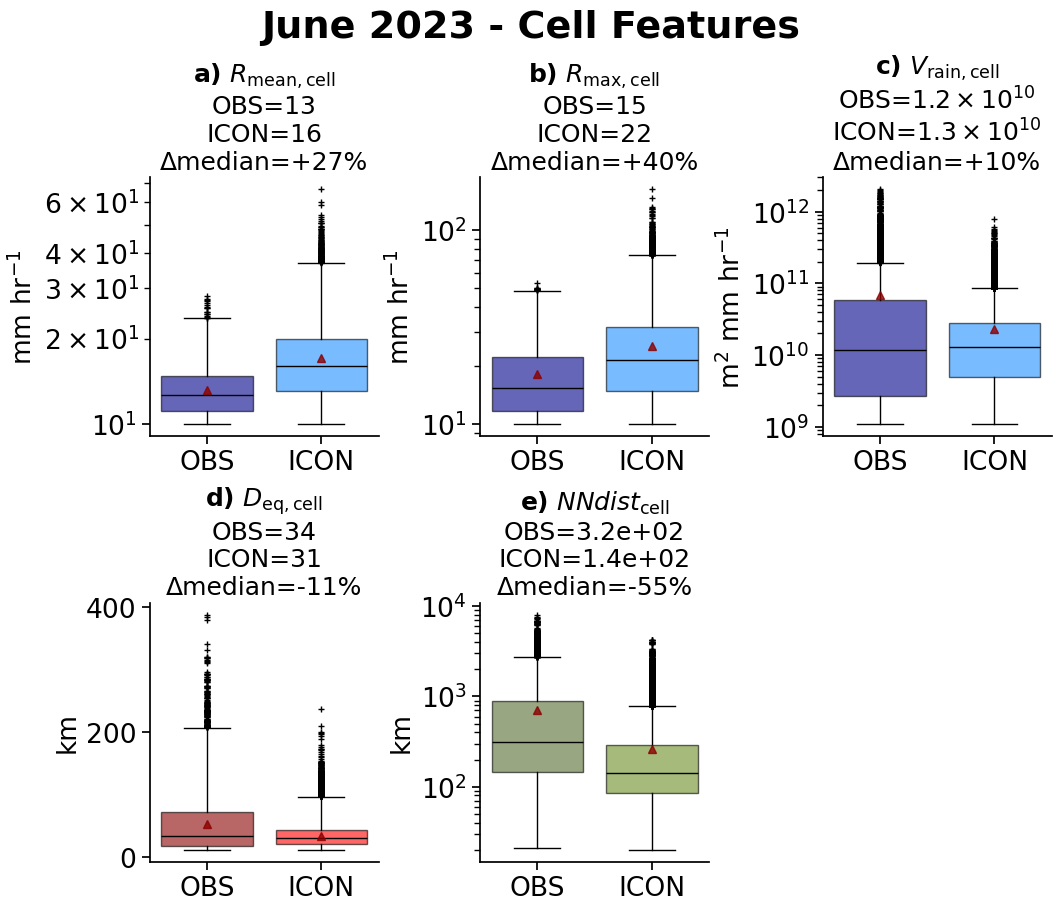

In [9]:
var_order_cell_features = ['mean_precip_cell',
 'max_precip_cell',
 'rain_volume_cell',
 'd_eq_cell',
 'min_dist_cell_km',
# 'n_sister_cells',
# 'mean_iwp_cell'
                          ]
VAR_META_ICON= defs_application.make_var_meta(var_order_cell_features, source="ICON")
VAR_META_OBS= defs_application.make_var_meta(var_order_cell_features, source="OBS")

# pdfs
plots_figs.quick_histograms(cellfeatures,
                var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS,
                 vars_to_plot = var_order_cell_features, vars_not_plot = ["time","num_cell","feature", "time_track"]
                ,nbins = 50, y_label = "PDF", title= f"{month_label} 2023 - Cell Featues",month = month,
                           groupbykey = "M" ,groupbykey_for_uncertainty = "D", )
plt.savefig(os.path.join(savedir,f"cellfeatures_hist_{month}.pdf"),bbox_inches="tight")
plt.show()

# boxplots 
plots_figs.quick_boxplots_reduced(cellfeatures,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_cell_features, vars_not_plot = ["time","num_cell","feature", "time_track"], 
                          title = f"{month_label} 2023 - Cell Features",month = month,
                         fontsizesubplots = 18)
plt.savefig(os.path.join(savedir,f"cellfeatures_box_{month}.pdf"),bbox_inches="tight")

plt.show()

# for medians 
plots_figs.quick_boxplots(cellfeatures,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_cell_features, vars_not_plot = ["time","num_cell","feature", "time_track"], 
                          title = f"{month_label} 2023 - Cell Features",month = month,
                         fontsizesubplots = 18)

plt.show()

# domain

In [10]:
var_order_domain

['n_cells',
 'cell_area_sum',
 'rain_volume_cell_sum',
 'n_anvils',
 'anvil_area_sum',
 'rain_volume_anvil_sum']

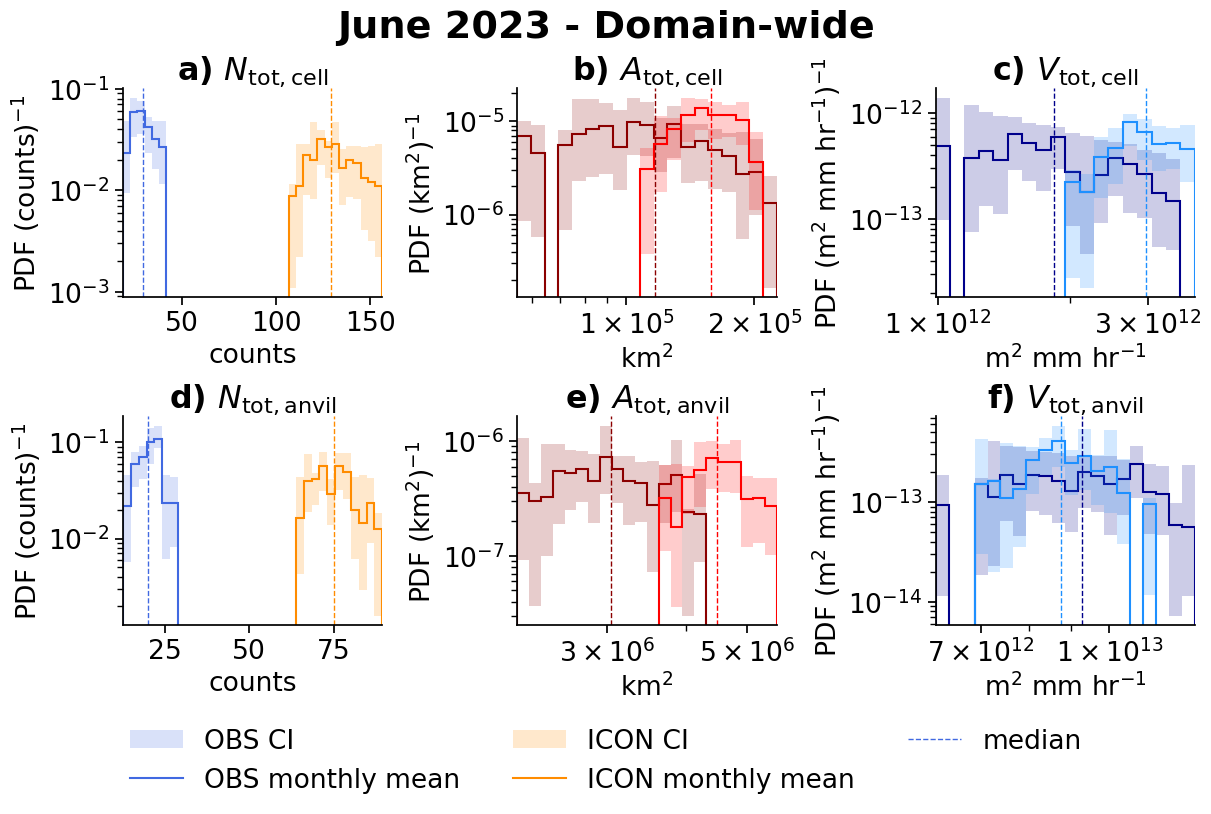

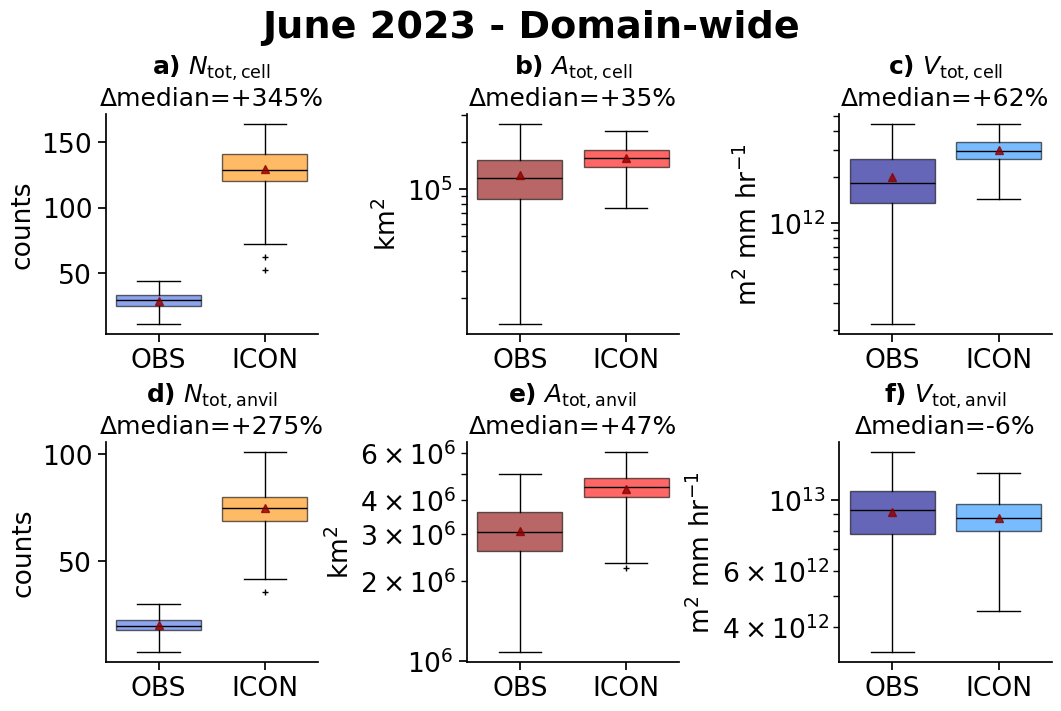

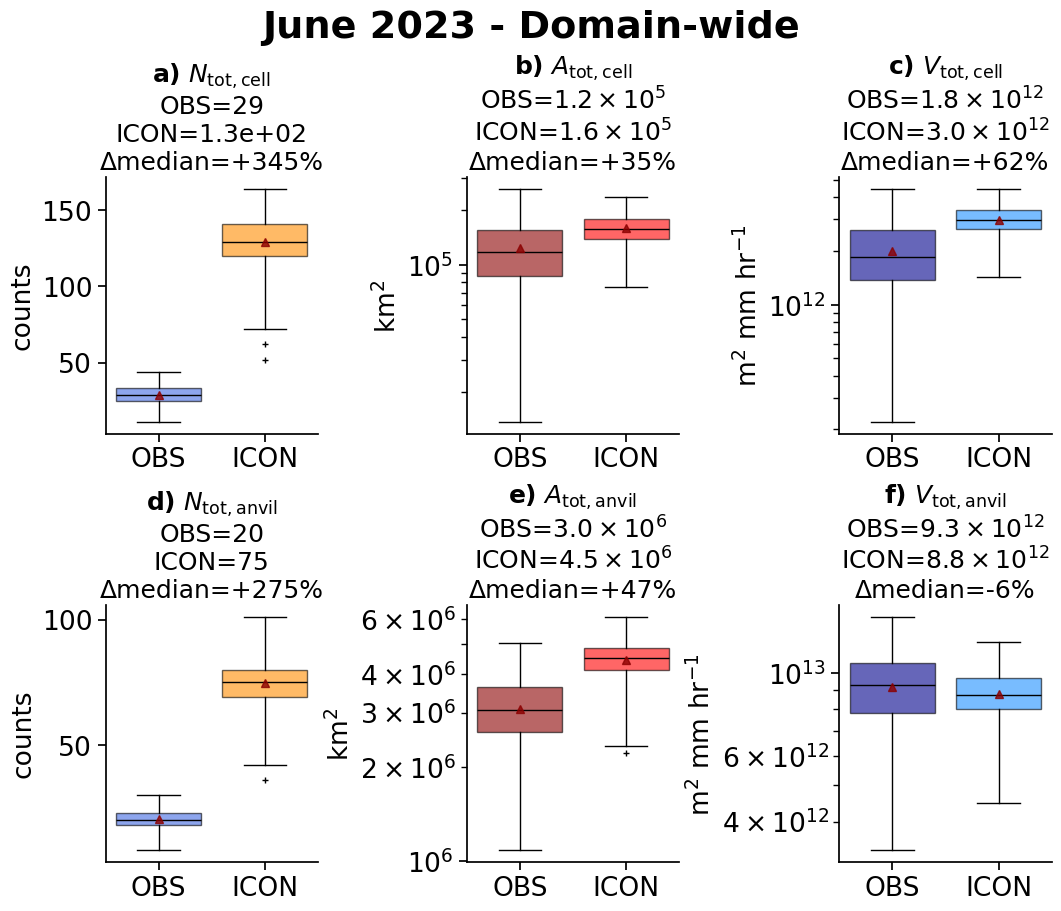

In [11]:
VAR_META_ICON= defs_application.make_var_meta(var_order_domain, source="ICON")
VAR_META_OBS= defs_application.make_var_meta(var_order_domain, source="OBS")

# pdfs
plots_figs.quick_histograms(domain,
                  var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS,
                 vars_to_plot = var_order_domain, vars_not_plot = ["time"],
                 ncols = 3, nbins = 40 , y_label = "PDF", title = f"{month_label} 2023 - Domain-wide",month = month,
                           groupbykey = "M" ,groupbykey_for_uncertainty = "D", )
plt.savefig(os.path.join(savedir,f"domain_hist_{month}.pdf"),bbox_inches="tight")
plt.show()

# boxplots 
plots_figs.quick_boxplots_reduced(domain,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_domain, vars_not_plot = ["time"],ncols = 3, title = f"{month_label} 2023 - Domain-wide",month = month,fontsizesubplots = 18)
plt.savefig(os.path.join(savedir,f"domain_box_{month}.pdf"),bbox_inches="tight")

plt.show()

# for medians
plots_figs.quick_boxplots(domain,var_meta_icon = VAR_META_ICON,
                 var_meta_obs = VAR_META_OBS, vars_to_plot =var_order_domain, vars_not_plot = ["time"],ncols = 3, title = f"{month_label} 2023 - Domain-wide",month = month,fontsizesubplots = 18)

plt.show()

# other stuff

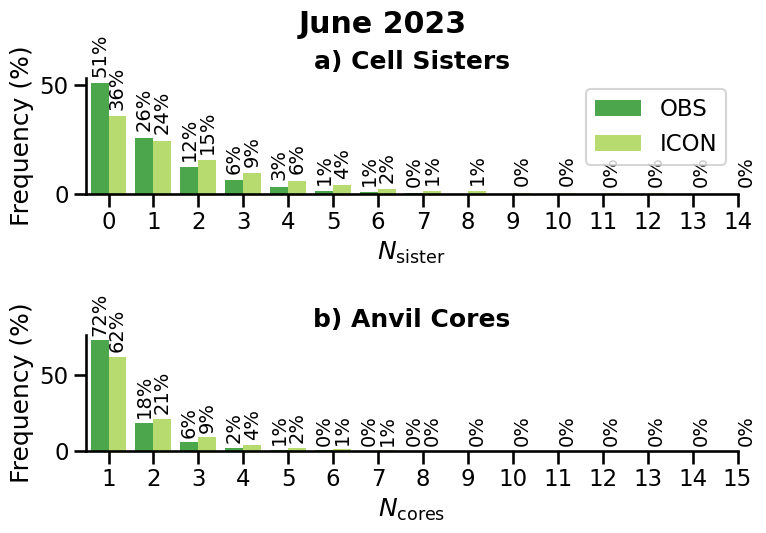

In [12]:
def plot_n_sister_cells(ds, var="n_sister_cells", month="JUNE", as_percent=True, fig = None, ax = None, title= "",startxat = 0,printlegend= True, xlabel = None,
                       color_obs = defs_application.color_n_obs, color_icon = defs_application.color_n_icon ):
    
    obs_vals = ds["OBS"][month][var].dropna()
    icon_vals = ds["ICON"][month][var].dropna()

    # shared integer bins across both datasets
    combined = pd.concat([obs_vals, icon_vals])
    max_val = int(combined.max())
    categories = np.arange(0, max_val + 1)

    obs_counts = obs_vals.value_counts(normalize=as_percent).reindex(categories, fill_value=0)
    icon_counts = icon_vals.value_counts(normalize=as_percent).reindex(categories, fill_value=0)

    if as_percent:
        obs_counts *= 100
        icon_counts *= 100

    x = np.arange(len(categories))
    width = 0.4

    if fig is None and ax is none:
        fig, ax = plt.subplots(figsize=(12, 5))
    bars_obs = ax.bar(x - width/2, obs_counts.values, width, label="OBS", color= color_obs, alpha=0.7)
    bars_icon = ax.bar(x + width/2, icon_counts.values, width, label="ICON", color=color_icon, alpha=0.7)

    # % labels on top of each bar
    for bars in (bars_obs, bars_icon):
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.text(bar.get_x() + bar.get_width()/2, height +3,
                         f"{height:.0f}%", ha="center", va="bottom", fontsize=14, rotation=90)

    ax.set_xticks(x)
    ax.set_xlim(startxat-0.5,max_val)
    ax.set_xticklabels(categories)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequency (%)" if as_percent else "Count")
    ax.set_title(title, fontweight = "bold")
    #ax.set_yscale("log")
    ax.grid(False)
    if printlegend: 
        ax.legend()

    fig.tight_layout()
    sns.despine()
    return fig

sns.set_context("talk")
fig, ax = plt.subplots(2,1,figsize=(8, 6))
fig = plot_n_sister_cells(cellfeatures, "n_sister_cells", fig = fig, ax = ax[0], title = "a) Cell Sisters", month = month, xlabel =  r'$N_{\mathrm{sister}}$')
fig = plot_n_sister_cells(anvilfeatures, "n_children_anvil",fig = fig, ax = ax[1], title = "b) Anvil Cores", startxat = 1, printlegend = False, month = month, xlabel =  r'$N_{\mathrm{cores}}$')
fig.suptitle(f"{month_label} 2023", fontweight = "bold", y= 0.9)
fig.tight_layout()
plt.savefig(os.path.join(savedir,f"nchildren_anvil_comparison_to _sisters_{month}.pdf"),bbox_inches="tight")
